# Collateral, the margin period of risk and initial margin

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the exposure of one swap)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- compute the credit support amount and the delivery amount of a margin agreement with a threshold and a minimum transfer amount, and read each case of the rule;
- state the supervisory floors of the margin period of risk (MPoR) and how re-margining frequency lengthens it;
- explain the close-out grid and the sticky-date close-out value, and why a collateralised exposure is still positive;
- compute the exposure of the netting set under a CSA with a 10-day and a 20-day MPoR and compare it with the uncollateralised one;
- compute the regression dynamic initial margin (DIM), apply it, and say why the ISDA SIMM weights are not reimplemented.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import collateral as col
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The data are three variants of case C12 (counterparty credit risk), on the same four synthetic swaps and the same US Treasury curve of 2025-09-30 as notebook 01. The trades are conventions of the case, the market inputs are real, and every number below is rebuilt from the committed curve, calibration, seed and number of paths.

- **Files read:** `data/derived/C12/netting-set.json` (curve, calibration and the four swaps, uncollateralised), `csa-mpor-10d.json` and `csa-mpor-20d.json` (a CSA with zero threshold, a 10,000 USD minimum transfer amount and daily re-margining, with an MPoR of 10 and 20 business days) and `with-im.json` (the 10-day CSA plus initial margin).
- **What each variant adds:** the `collateral` block holds the agreement and the mean collateral balance; the `initial_margin` block holds the DIM.
- **Limits stated by the document:** the Andersen, Pykhtin and Sokol (2017) timelines are not modelled, and the DIM is a regression proxy, never SIMM.

The next cell loads the four documents and prints the agreement and the initial-margin method.

In [2]:
# Load the four committed documents of C12 (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
docs = {name: json.loads((derived / f"{name}.json").read_text(encoding="utf-8")) for name in ("netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im")}
base = docs["netting-set"]["outputs"]

print("baked by riskvalidation", docs["csa-mpor-10d"]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
csa = docs["csa-mpor-10d"]["outputs"]["collateral"]["csa"]
for key in ("threshold", "minimum_transfer_amount", "independent_amount"):
    print(f"{key:26s}", csa[key]["amount"], csa[key]["currency"])
print("MPoR (business days), 10-day variant:", csa["mpor_business_days"], "| 20-day variant:", docs["csa-mpor-20d"]["outputs"]["collateral"]["csa"]["mpor_business_days"])
print("re-margining every", csa["remargining_days"], "day(s)")
im = docs["with-im"]["outputs"]["initial_margin"]
print("initial margin by regression, SIMM used:", im["simm_used"])
print("quantile", im["quantile"], "| horizon / MPoR in calendar days", im["horizon_calendar_days"], "/", im["mpor_calendar_days"], "| regression order", im["regression_order"])

baked by riskvalidation 0.9.0 | installed 0.9.0
threshold                  0.0 USD
minimum_transfer_amount    10000.0 USD
independent_amount         0.0 USD
MPoR (business days), 10-day variant: 10 | 20-day variant: 20
re-margining every 1 day(s)
initial margin by regression, SIMM used: False
quantile 0.99 | horizon / MPoR in calendar days 14 / 14 | regression order 2


## Method

### Step 1: the credit support amount and the delivery amount

A margin agreement fixes how much collateral the two parties must hold for a given value of the netting set. With $x = \mathrm{NPV} + \mathrm{IA}$ (IA the independent amount), a receive threshold $Th_{rec}$ and a pay threshold $Th_{pay}$, the credit support amount is (ORE methodology, equation CSA):

$$\mathrm{CSA} = \begin{cases} \max(0,\ x - Th_{rec}) & x \ge 0 \\ \min(0,\ x + Th_{pay}) & x < 0 \end{cases}$$

The amount is positive when the bank holds collateral. The delivery amount moves the balance $C$ towards the CSA, but only when the call is big enough. With $M$ the calls already outstanding and $\mathrm{MTA}$ the minimum transfer amount, $\Delta = \mathrm{CSA} - C - M$ and the amount delivered is $D = \Delta$ if $|\Delta| \ge \mathrm{MTA}$ and 0 otherwise. The next cell evaluates both on a ladder of values, once with a zero threshold and once with a threshold of 100,000 USD, then shows what the minimum transfer amount does to a small call.

In [3]:
# The credit support amount on a ladder of values for two thresholds, and the delivery amount with a minimum transfer amount
npv = np.array([-300e3, -150e3, -20e3, 0.0, 5e3, 60e3, 150e3, 400e3])
csa_zero = col.credit_support_amount(npv, 0.0, 0.0, 0.0)
csa_100k = col.credit_support_amount(npv, 0.0, 100e3, 100e3)
print(f"{'NPV':>10s} {'CSA TH=0':>10s} {'CSA TH=100k':>12s}")
for v, c0, c1 in zip(npv, csa_zero, csa_100k):
    print(f"{v:10.0f} {c0:10.0f} {c1:12.0f}")

balance, outstanding, mta = np.zeros_like(npv), np.zeros_like(npv), 10e3
print("delivery with MTA = 10000 and an empty balance:", col.delivery_amount(csa_zero, balance, outstanding, mta))
print("delivery with MTA = 0:", col.delivery_amount(csa_zero, balance, outstanding, 0.0))

       NPV   CSA TH=0  CSA TH=100k
   -300000    -300000      -200000
   -150000    -150000       -50000
    -20000     -20000            0
         0          0            0
      5000       5000            0
     60000      60000            0
    150000     150000        50000
    400000     400000       300000
delivery with MTA = 10000 and an empty balance: [-300000. -150000.  -20000.       0.       0.   60000.  150000.  400000.]
delivery with MTA = 0: [-300000. -150000.  -20000.       0.    5000.   60000.  150000.  400000.]


### Step 2: the margin period of risk

When a counterparty stops paying, the bank does not close the position the same day. The MPoR is the time between the last margin the bank received and the moment the position is closed out and re-hedged. During it the value moves and nobody posts margin, so the collateral held lags the value. The Basel floors are (CRE53.24 to CRE53.26): 10 business days, 5 for repo-style sets, 20 if the set has more than 5,000 trades or illiquid collateral, doubled if there were more than two long disputes in two quarters; and with re-margining every $N$ days the period is $F + N - 1$. The engine's `mpor_floor` and `mpor_with_remargining` return these numbers. The case uses 10 and 20 business days, which it converts to 14 and 28 calendar days because ORE counts the close-out in calendar days.

In [4]:
# The supervisory floors of the MPoR and the effect of re-margining, by calling the engine
print("default floor:", col.mpor_floor())
print("repo-style netting set:", col.mpor_floor(repo_only=True))
print("more than 5000 trades:", col.mpor_floor(n_trades=5001))
print("illiquid collateral:", col.mpor_floor(illiquid=True))
print("more than two disputes, default floor:", col.mpor_floor(disputes_over_two=True))
for days in (1, 5, 10):
    print(f"re-margining every {days:2d} day(s): MPoR =", col.mpor_with_remargining(10, days), "business days")

deltas = {10: 14 / 360, 20: 28 / 360}
print("close-out offsets in years on the 30/360 axis:", {bd: round(d, 6) for bd, d in deltas.items()})

default floor: 10
repo-style netting set: 5
more than 5000 trades: 20
illiquid collateral: 20
more than two disputes, default floor: 20
re-margining every  1 day(s): MPoR = 10 business days
re-margining every  5 day(s): MPoR = 14 business days
re-margining every 10 day(s): MPoR = 19 business days
close-out offsets in years on the 30/360 axis: {10: 0.038889, 20: 0.077778}


### Step 3: the simulation and the sticky-date close-out

We rebuild the simulation of notebook 01 (same curve, calibration, seed and grid, with the close-out dates on the grid). The close-out value for a default at date $t$ is the value of the netting set at $t + \delta$, where $\delta$ is the MPoR in years. ORE offers two ways to read it; the case uses the **sticky-date** one: the market has moved to $t+\delta$, but the portfolio has not aged, so a swap at $t+\delta$ keeps the same remaining flows it had at $t$. Valuing the swap rolled forward by $\delta$ at $t+\delta$ gives exactly that, and the coupon of a period already begun is the one fixed on the path at its last reset. The next cell rebuilds the paths, the values at the report dates and the sticky close-out values for both MPoR.

In [5]:
# Rebuild the paths of notebook 01, the netting-set values at the report dates and the sticky close-out values for both MPoR
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer", t["start_years"], t["maturity_years"],
                 t["fixed_frequency_per_year"]) for t in base["book"]["trades"]]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in deltas.values()]), 12))
grid = sw.simulation_grid(merged, swaps)
r = hw1f.simulate_short_rate(grid, a, sigma, forward, named["path_count"]["value"], named["seed"]["value"])
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix_main = np.searchsorted(grid, main - sw.TIME_TOL)
vm = ex.net_values(values[:, :, ix_main])

ROLL = 1e-7
closeout = {}
for bd, delta in deltas.items():
    cube = np.zeros((len(swaps), r.shape[0], main.size))
    for s_i, swap in enumerate(swaps):
        shifted = sw.Swap(swap.trade_id, swap.notional, swap.fixed_rate, swap.is_payer, swap.start + delta - ROLL,
                          swap.maturity + delta - ROLL, swap.fixed_frequency)
        resets, times = sw.reset_times(swap), sw.cash_flow_times(swap)
        for k, t in enumerate(main):
            if t >= swap.maturity - sw.TIME_TOL:
                continue
            j = int(np.searchsorted(resets, t + sw.TIME_TOL, side="right")) - 1
            i_reset = np.searchsorted(grid, resets[j] - sw.TIME_TOL)
            p_fix = hw1f.bond_price(r[:, i_reset], float(resets[j]), float(times[j]), a, sigma, p0, forward)
            fixing = (1.0 / p_fix - 1.0) / float(times[j] - resets[j])
            i_close = np.searchsorted(grid, t + delta - sw.TIME_TOL)
            cube[s_i, :, k] = sw.swap_value(shifted, float(t + delta), r[:, i_close], a, sigma, p0, forward, fixing)
    closeout[bd] = ex.net_values(cube)

print("netting-set values (paths, dates):", vm.shape)
print("close-out values for MPoR of 10 and 20 days:", {bd: v.shape for bd, v in closeout.items()})
print("mean absolute gap between close-out value and value, 10-day / 20-day:",
      round(float(np.abs(closeout[10] - vm).mean()), 0), "/", round(float(np.abs(closeout[20] - vm).mean()), 0))

netting-set values (paths, dates): (20000, 34)
close-out values for MPoR of 10 and 20 days: {10: (20000, 34), 20: (20000, 34)}
mean absolute gap between close-out value and value, 10-day / 20-day: 33239.0 / 46978.0


### Step 4: the exposure under variation margin

Date by date, the engine's `variation_margin_exposure` runs the credit support and delivery rules on the values at the main dates to get the balance $C(t)$, and then takes the exposure on the close-out values:

$$E(t) = \max\big(V_{closeout}(t) - C(t),\ 0\big)$$

This is Hull and White's equation 4: the exposure is positive even with a zero threshold because the collateral lags the value by the MPoR, and it tends to zero as the MPoR does. `collateralised_exposure` is the same last step on its own. We compute the EE in the $t$-forward measure as in notebook 01, for 10 and 20 days, with the case's minimum transfer amount and with none, and compare with the committed documents.

In [6]:
# EE under variation margin for both MPoR, with and without the minimum transfer amount, against the committed documents
ix = ix_main[1:]
p0r = p0(report)
nm = numeraire[:, ix]
th, mta_case, ia = csa["threshold"]["amount"], csa["minimum_transfer_amount"]["amount"], csa["independent_amount"]["amount"]

ee_unc = ex.expected_exposure(vm[:, 1:], nm)[0] / p0r
profile = {"unc": ee_unc}
eepe = {"unc": ex.effective_epe(report, ex.effective_ee(ee_unc))}
for bd, label in ((10, "10d"), (20, "20d")):
    x, held = col.variation_margin_exposure(vm, closeout[bd], ia, th, th, mta_case)
    ee_bd = ex.expected_exposure(x[:, 1:], nm)[0] / p0r
    profile[label], eepe[label] = ee_bd, ex.effective_epe(report, ex.effective_ee(ee_bd))
    same = col.collateralised_exposure(closeout[bd], held)
    committed = np.array(docs[f"csa-mpor-{label}"]["outputs"]["exposure"]["ee"]["values"])
    print(f"MPoR {bd} days: gap to the committed EE", float(np.max(np.abs(ee_bd - committed))),
          "| collateralised_exposure equals the engine exposure:", bool(np.allclose(same, x)))
    x0, _ = col.variation_margin_exposure(vm, closeout[bd], ia, th, th, 0.0)
    eepe[label + "-mta0"] = ex.effective_epe(report, ex.effective_ee(ex.expected_exposure(x0[:, 1:], nm)[0] / p0r))

k1 = np.searchsorted(report, 1.0 - 1e-9)
print(f"{'':16s}{'EEPE':>10s}{'EE at 1 y':>12s}")
for key, label in (("unc", "uncollateralised"), ("10d", "CSA, 10 days"), ("20d", "CSA, 20 days")):
    print(f"{label:16s}{eepe[key]:10.0f}{profile[key][k1]:12.0f}")
print("EEPE without the minimum transfer amount, 10 / 20 days:", round(eepe["10d-mta0"], 0), "/", round(eepe["20d-mta0"], 0))
print("EEPE committed, 10 / 20 days:", round(docs["csa-mpor-10d"]["outputs"]["exposure"]["eepe"]["amount"], 0), "/", round(docs["csa-mpor-20d"]["outputs"]["exposure"]["eepe"]["amount"], 0))

MPoR 10 days: gap to the committed EE 0.0 | collateralised_exposure equals the engine exposure: True
MPoR 20 days: gap to the committed EE 0.0 | collateralised_exposure equals the engine exposure: True
                      EEPE   EE at 1 y
uncollateralised     59954      101950
CSA, 10 days         22778       20811
CSA, 20 days         33183       30126
EEPE without the minimum transfer amount, 10 / 20 days: 22756.0 / 33173.0
EEPE committed, 10 / 20 days: 22778.0 / 33183.0


### Step 5: dynamic initial margin

Initial margin is posted in addition to variation margin and covers the change of value during the MPoR. ORE estimates it path by path with a regression (ORE methodology; addendum R2 of the case research). At each date it forms the change over the MPoR $X = V(t+\mathrm{MPoR}) + F - V(t)$, with $F$ the flows inside the window (zero here), regresses $X^2$ on a polynomial of the current value to get $E[X^2 \mid V(t)]$, and sets

$$S = \sqrt{\max(E[X^2 \mid V(t)] - E[X]^2,\ 0)}, \qquad \mathrm{DIM}(t) = \Phi^{-1}(q)\ S\ \sqrt{h / m}$$

with $q = 99\%$ and $h$ and $m$ the horizon and the MPoR in **calendar** days (14 and 14). Then the exposure becomes $\max(E - \mathrm{DIM}, 0)$ path by path, applied only on top of variation margin. This is a proxy of a trade-level model: the ISDA SIMM risk weights are published under a notice that restricts their use to a participant's own transactions, so the engine does not reimplement them and the document labels the result `regression proxy, not SIMM`. The next cell computes the DIM at every date, applies it and compares with the committed `with-im.json`.

In [7]:
# The regression DIM at every date, applied path by path to the 10-day variation-margin exposure, against with-im.json
x_vm, held = col.variation_margin_exposure(vm, closeout[10], ia, th, th, mta_case)
dim = np.column_stack([
    col.dynamic_initial_margin(vm[:, k], closeout[10][:, k], np.zeros(vm.shape[0]), im["quantile"], im["horizon_calendar_days"],
                               im["mpor_calendar_days"], im["regression_order"])
    for k in range(vm.shape[1])
])
x_im = col.apply_initial_margin(x_vm[:, 1:], dim[:, 1:])
ee_vm = ex.expected_exposure(x_vm[:, 1:], nm)[0] / p0r
ee_im = ex.expected_exposure(x_im, nm)[0] / p0r
doc = docs["with-im"]["outputs"]
dim_mean = dim[:, 1:].mean(axis=0)

print("gap to the committed EE with IM:", float(np.max(np.abs(ee_im - np.array(doc["exposure"]["ee"]["values"])))))
print("gap to the committed mean DIM:", float(np.max(np.abs(dim_mean - np.array(doc["initial_margin"]["dim"]["values"])))))
print("gap to the committed EE before IM:", float(np.max(np.abs(ee_vm - np.array(doc["initial_margin"]["ee_vm_only"]["values"])))))
print("DIM is never negative and the exposure never rises:", bool(dim.min() >= 0), bool(np.all(x_im <= x_vm[:, 1:] + 1e-9)))
print("mean DIM at 1 y:", round(float(dim_mean[k1]), 0), "| EE before / after IM at 1 y:", round(float(ee_vm[k1]), 0), "/", round(float(ee_im[k1]), 0))
print("EEPE before / after IM:", round(ex.effective_epe(report, ex.effective_ee(ee_vm)), 0), "/", round(ex.effective_epe(report, ex.effective_ee(ee_im)), 0))
print("alpha = Phi^-1(q):", round(im["alpha"], 6), "| document limit:", im["limit"]["en"][:90], "...")

gap to the committed EE with IM: 0.0
gap to the committed mean DIM: 0.0
gap to the committed EE before IM: 0.0
DIM is never negative and the exposure never rises: True True
mean DIM at 1 y: 110493.0 | EE before / after IM at 1 y: 20811.0 / 178.0
EEPE before / after IM: 22778.0 / 213.0
alpha = Phi^-1(q): 2.326348 | document limit: A regression proxy, never SIMM. The DIM reduces the exposure path by path, E[max(X - DIM,  ...


The last cell draws the lesson: the expected exposure of the netting set without collateral, with a CSA of 10 and 20 days, and with initial margin on top of the 10-day CSA, and the mean DIM the last one used.

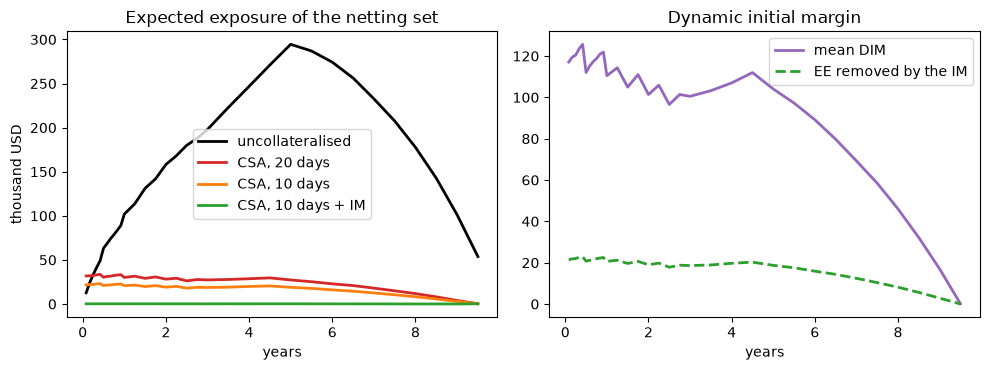

In [8]:
# Draw the EE under the four regimes (left) and the mean DIM with the EE it removes (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(report, ee_unc / 1e3, color="black", lw=2, label="uncollateralised")
left.plot(report, profile["20d"] / 1e3, color="tab:red", lw=2, label="CSA, 20 days")
left.plot(report, profile["10d"] / 1e3, color="tab:orange", lw=2, label="CSA, 10 days")
left.plot(report, ee_im / 1e3, color="tab:green", lw=2, label="CSA, 10 days + IM")
left.set_xlabel("years")
left.set_ylabel("thousand USD")
left.set_title("Expected exposure of the netting set")
left.legend()
right.plot(report, dim_mean / 1e3, color="tab:purple", lw=2, label="mean DIM")
right.plot(report, (ee_vm - ee_im) / 1e3, color="tab:green", lw=2, ls="--", label="EE removed by the IM")
right.set_xlabel("years")
right.set_title("Dynamic initial margin")
right.legend()
fig.tight_layout()
plt.show()

## Results

- **The rule.** With a zero threshold the credit support amount equals the value (the bank holds all it is owed, and posts all it owes). A threshold of 100,000 USD leaves the first 100,000 uncollateralised: a value of 60,000 needs no collateral and 400,000 needs 300,000. The minimum transfer amount is a dead zone: a call of 5,000 USD is not delivered when the MTA is 10,000, and is delivered when the MTA is zero.
- **The period.** The floor is 10 business days by default, 5 for repo-style sets, and 20 for sets of more than 5,000 trades, with illiquid collateral, or doubled after long disputes. Re-margining every 5 days lengthens it to 14 business days, and every 10 days to 19: the period is $F + N - 1$. The case's 10 and 20 days become close-out offsets of 0.0389 and 0.0778 years on the 30/360 axis, and the average absolute gap between the close-out value and the value at the default date is 33,239 USD for 10 days and 46,978 USD for 20.
- **The exposure.** Without collateral the netting set has an EEPE of 59,954 USD. With a CSA of 10 days it falls to 22,778 USD (a reduction of 62%), and with 20 days to 33,183 USD (a reduction of 45%). Collateral cuts the exposure and does not remove it: the value moves during the MPoR, and doubling the MPoR raises the EEPE by 46%. The minimum transfer amount matters little here: without it the EEPE would be 22,756 and 33,173 USD.
- **Initial margin.** The regression DIM has a mean of 110,493 USD at one year. Applied on top of the 10-day CSA it takes the EE at one year from 20,811 USD to 178 USD and the EEPE from 22,778 USD to 213 USD. Read this as the proxy's answer and not as a capital number: notebook 07 and 08 show that ORE's own dynamic initial margin differs from this one, and the committed document reports that gap as a finding.
- **Reproduction.** Every profile rebuilt here (the two CSA variants, the EE before and after IM and the mean DIM) differs from the committed document by exactly 0.0.

What this notebook does not show: what the collateral costs or saves in CVA (notebook 03), the SA-CCR treatment of a margined set (notebook 04) and the reconciliation with ORE (notebooks 07 and 08).

## Summary

- The credit support amount depends on the value, the threshold and the independent amount; the delivery amount moves the balance only when the call reaches the minimum transfer amount.
- The MPoR has supervisory floors (10, 5 or 20 business days, doubled after disputes) and grows with the re-margining interval as $F + N - 1$.
- A collateralised exposure is $\max(V_{closeout} - C, 0)$: still positive because the collateral lags the value, and growing with the MPoR (here +46% of EEPE from 10 to 20 days).
- The regression DIM, $\Phi^{-1}(q) S \sqrt{h/m}$, takes most of that remainder away in this book; it is a proxy and ORE does not agree with it.

**What to try next.** Change the threshold to 100,000 USD in the `variation_margin_exposure` call and see how much of the 10-day exposure returns; set the regression order to 0 and see what the DIM loses. Then continue with notebook 03.

## References

- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- Andersen, L., Pykhtin, M. and Sokol, A. (2017), Rethinking the margin period of risk, Journal of Credit Risk 13(1). https://doi.org/10.21314/JCR.2016.218
- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6